# Exercise 4 — Convolutional Neural Networks (CNNs)

**Task:** Multi-class image classification on Fashion-MNIST using PyTorch.

**Workflow:** Prepare a reproducible train/validation split, define a CNN, compare a normalized baseline with an affine-augmentation + learning-rate-scheduler configuration, select the checkpoint by validation loss, and evaluate it once on the held-out test set. The notebook also visualizes learning curves, a confusion matrix, learned filters, and feature maps.

**Important:** The results discussed below refer to the saved execution outputs in this notebook. Running it again can yield slightly different values.


In [110]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, random_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## 1. Reproducibility and computational environment

The experiment fixes the Python, NumPy, and PyTorch random seeds to **42**. CUDA is used if available; otherwise, the code runs on the CPU. Setting seeds improves repeatability, although hardware and backend differences can still lead to small numerical variations.


In [111]:
# A single fixed split is reused in both experiments.
BATCH_SIZE = 64
raw_dataset = datasets.FashionMNIST('./data', train=True, download=True,
                                    transform=transforms.ToTensor())
train_subset, val_subset = random_split(
    raw_dataset, [54_000, 6_000], generator=torch.Generator().manual_seed(SEED))

clean_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])
clean_dataset = datasets.FashionMNIST('./data', train=True, download=True,
                                     transform=clean_transform)
final_train_dataset = Subset(clean_dataset, train_subset.indices)
final_val_dataset = Subset(clean_dataset, val_subset.indices)
final_train_loader = DataLoader(final_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
final_val_loader = DataLoader(
    final_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(
    f'Train: {len(final_train_dataset):,} | '
    f'Validation: {len(final_val_dataset):,}'
)

Train: 54,000 | Validation: 6,000


## 2. Dataset and preprocessing

**Fashion-MNIST** contains grayscale **28 × 28** images of clothing items belonging to **10 classes**. The original 60,000 training examples are split reproducibly into **54,000 training** and **6,000 validation** images. The separate **10,000-image test set** is reserved for final evaluation.

All validation and test images use `ToTensor()` followed by normalization with mean **0.2860** and standard deviation **0.3530**. The baseline training images use the same normalization. The same train/validation indices are reused in both configurations to make the comparison more meaningful. The batch size is **64** in both experiments.


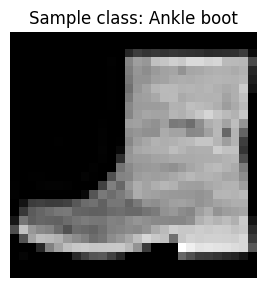

In [112]:
sample, target = final_train_dataset[0]
plt.figure(figsize=(3.2, 3.2))
plt.imshow((sample.squeeze() * 0.3530 + 0.2860).clamp(0, 1), cmap='gray')
plt.title(f'Sample class: {clean_dataset.classes[target]}')
plt.axis('off')
plt.show()

### 2.1 Example image

The following cell displays one normalized training image after reversing normalization for visualization. This is a sanity check of the input format and class labels, not an evaluation of the model.


In [113]:
import torch
import torch.nn as nn

class FashionCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolutional block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

## 3. CNN architecture

The network uses three blocks of **3 × 3 convolution → ReLU → 2 × 2 max pooling** with **32**, **64**, and **128** output channels. Pooling reduces the spatial resolution from **28 × 28 → 14 × 14 → 7 × 7 → 3 × 3**. A flattening operation is followed by a **128-unit fully connected layer**, ReLU, **dropout = 0.3**, and a final linear layer with **10 logits**.

The final layer intentionally has **no softmax**: `CrossEntropyLoss` expects unnormalized logits and applies the numerically stable log-softmax internally.


In [114]:
architecture = FashionCNN()
print(architecture)
print(f'Trainable parameters: {sum(p.numel() for p in architecture.parameters() if p.requires_grad):,}')

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1152, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 241,546


### 3.1 Architecture inspection

The next cell prints the model and computes the number of trainable parameters directly from the PyTorch modules. This helps document model complexity without estimating it from file size or training time.


In [115]:
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)

final_model = FashionCNN().to(device)

final_criterion = nn.CrossEntropyLoss()

final_optimizer = optim.Adam(
    final_model.parameters(),
    lr=0.001
)

best_val_loss = float("inf")
best_epoch = 0

print("Final model created!")

Final model created!


## 4. Experiment A — Normalized baseline

**Setup:** The CNN is initialized from scratch and trained for **20 epochs** with **Adam (`lr = 0.001`)**, cross-entropy loss, **batch size 64**, and **no data augmentation or learning-rate scheduler**. After every epoch, the model is evaluated on the validation split. Whenever validation loss decreases, a checkpoint is saved to `best_fashion_cnn.pth`.

**Selection rule:** The checkpoint with the **lowest validation loss** is kept; the final epoch is not assumed to be best. This selection uses no test labels.


In [116]:
num_epochs = 20

final_train_losses = []
final_val_losses = []

final_train_accuracies = []
final_val_accuracies = []

for epoch in range(num_epochs):

    # ===== TRAINING =====
    final_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in final_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        final_optimizer.zero_grad()

        outputs = final_model(images)

        loss = final_criterion(outputs, labels)

        loss.backward()
        final_optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # ===== VALIDATION =====
    final_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in final_val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = final_model(images)

            loss = final_criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    final_train_losses.append(train_loss)
    final_val_losses.append(val_loss)

    final_train_accuracies.append(train_accuracy)
    final_val_accuracies.append(val_accuracy)

    # ===== SAVE BEST MODEL =====
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            final_model.state_dict(),
            "best_fashion_cnn.pth"
        )

        print(f"New best model saved! epoch {best_epoch}")

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

New best model saved! epoch 1
Epoch 1/20 | Train Loss: 0.5430 | Val Loss: 0.3306 | Val Accuracy: 87.60%
New best model saved! epoch 2
Epoch 2/20 | Train Loss: 0.3288 | Val Loss: 0.2910 | Val Accuracy: 88.88%
New best model saved! epoch 3
Epoch 3/20 | Train Loss: 0.2813 | Val Loss: 0.2707 | Val Accuracy: 90.20%
New best model saved! epoch 4
Epoch 4/20 | Train Loss: 0.2508 | Val Loss: 0.2580 | Val Accuracy: 90.27%
New best model saved! epoch 5
Epoch 5/20 | Train Loss: 0.2274 | Val Loss: 0.2270 | Val Accuracy: 91.35%
New best model saved! epoch 6
Epoch 6/20 | Train Loss: 0.2061 | Val Loss: 0.2269 | Val Accuracy: 91.95%
New best model saved! epoch 7
Epoch 7/20 | Train Loss: 0.1886 | Val Loss: 0.2247 | Val Accuracy: 92.12%
New best model saved! epoch 8
Epoch 8/20 | Train Loss: 0.1716 | Val Loss: 0.2158 | Val Accuracy: 92.07%
Epoch 9/20 | Train Loss: 0.1600 | Val Loss: 0.2308 | Val Accuracy: 91.90%
Epoch 10/20 | Train Loss: 0.1453 | Val Loss: 0.2232 | Val Accuracy: 92.43%
Epoch 11/20 | Train

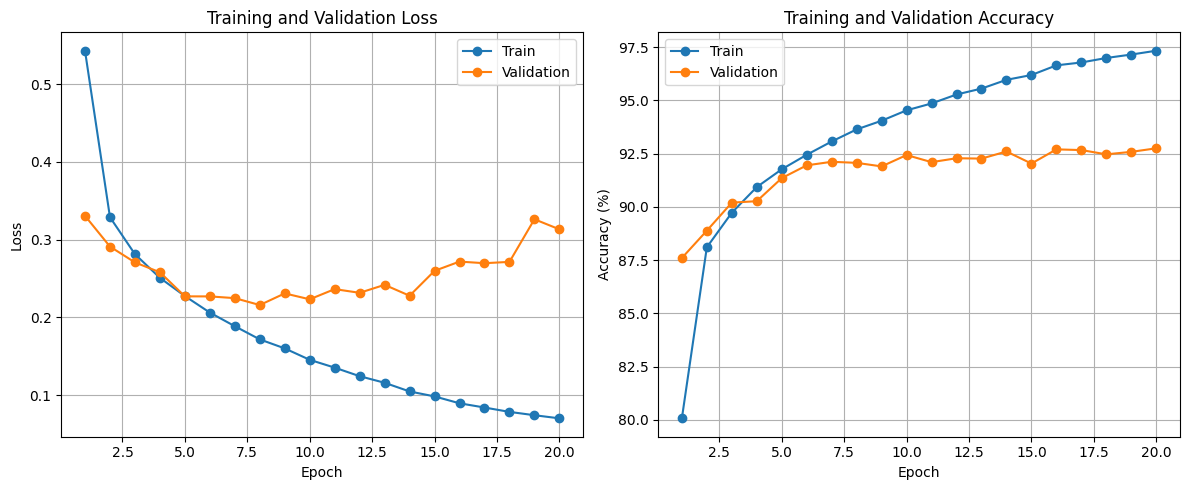

In [117]:
import matplotlib.pyplot as plt

epochs = range(1, len(final_train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    epochs, final_train_losses,
    marker="o", label="Train"
)
axes[0].plot(
    epochs, final_val_losses,
    marker="o", label="Validation"
)
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs, final_train_accuracies,
    marker="o", label="Train"
)
axes[1].plot(
    epochs, final_val_accuracies,
    marker="o", label="Validation"
)
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("final_training_curves.png", dpi=300)
plt.show()

### 4.1 Baseline learning-curve interpretation

The training loss decreases across the 20 epochs, but validation loss reaches its minimum of **0.2158 at epoch 8** and later rises while training loss continues to fall. This is evidence of a growing **generalization gap / overfitting** in later epochs. Consequently, retaining the epoch-8 checkpoint is preferable to blindly taking the epoch-20 model.

The two plotted metrics answer different questions: **loss** measures how well predicted class scores fit the labels, whereas **accuracy** measures the fraction of correctly classified examples. They do not necessarily attain their optima at the same epoch.


In [118]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

## 5. Experiment B — Affine augmentation and StepLR

The alternative configuration uses the **same architecture, train/validation split, batch size, initial learning rate, optimizer, and 20-epoch budget**. During training only, each image may be randomly rotated by up to **±10°**, translated by up to **5%** in each direction, and rescaled between **0.95 and 1.05**. Validation images remain unchanged apart from normalization.

A `StepLR` scheduler multiplies the learning rate by **0.5 every 3 epochs**. Starting the model from a fresh seeded initialization allows comparison with the baseline while keeping the original split fixed.

**Interpretation limitation:** Augmentation **and** the scheduler change together, so differences between Experiments A and B cannot be attributed to either component individually. A separate augmentation-only experiment would be needed to isolate effects.


In [119]:
from torchvision import datasets
from torch.utils.data import Subset, DataLoader

train_full = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

val_full = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=val_transform
)

train_augmented = Subset(
    train_full,
    train_subset.indices
)

val_clean = Subset(
    val_full,
    val_subset.indices
)

train_loader = DataLoader(
    train_augmented,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_clean,
    batch_size=64,
    shuffle=False
)

print("Train:", len(train_augmented))
print("Validation:", len(val_clean))

Train: 54000
Validation: 6000


In [120]:
import torch
import torch.optim as optim

# Initialize the alternative from the same fixed random seed as the baseline
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
model = FashionCNN().to(device)

# Create a fresh optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)


# Learning rate scheduler
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.5
)


print("Initial LR:", optimizer.param_groups[0]["lr"])

Initial LR: 0.001


In [121]:
criterion = nn.CrossEntropyLoss()  # same objective as the baseline

In [122]:
num_epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

learning_rates = []

# A separate checkpoint avoids overwriting the baseline weights.
aug_best_val_loss = float('inf')
aug_best_epoch = 0
aug_checkpoint = 'best_fashion_cnn_augmented.pth'

### 5.1 Training and checkpointing

The training loop records training and validation loss and accuracy, plus the learning rate used in each epoch. As in the baseline, it saves a **separate checkpoint** (`best_fashion_cnn_augmented.pth`) whenever validation loss improves. This prevents the augmented model from overwriting the baseline weights.


In [123]:
for epoch in range(num_epochs):

    # Save current learning rate
    current_lr = optimizer.param_groups[0]["lr"]
    learning_rates.append(current_lr)

    # ===== TRAINING =====
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # ===== VALIDATION =====
    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = running_val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    # ===== SAVE RESULTS =====
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"LR: {current_lr:.6f} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

    # Checkpoint only on validation loss (never on test performance).
    if val_loss < aug_best_val_loss:
        aug_best_val_loss = val_loss
        aug_best_epoch = epoch + 1
        torch.save(model.state_dict(), aug_checkpoint)
        print(f"New best model saved! epoch {aug_best_epoch}")

    # Update learning rate for the next epoch
    scheduler.step()

Epoch [1/20] | LR: 0.001000 | Train Loss: 0.6325 | Train Acc: 76.11% | Val Loss: 0.3844 | Val Acc: 85.63%
New best model saved! epoch 1
Epoch [2/20] | LR: 0.001000 | Train Loss: 0.4227 | Train Acc: 84.28% | Val Loss: 0.3558 | Val Acc: 86.20%
New best model saved! epoch 2
Epoch [3/20] | LR: 0.001000 | Train Loss: 0.3693 | Train Acc: 86.22% | Val Loss: 0.3063 | Val Acc: 88.70%
New best model saved! epoch 3
Epoch [4/20] | LR: 0.000500 | Train Loss: 0.3253 | Train Acc: 88.11% | Val Loss: 0.2780 | Val Acc: 89.62%
New best model saved! epoch 4
Epoch [5/20] | LR: 0.000500 | Train Loss: 0.3079 | Train Acc: 88.79% | Val Loss: 0.2631 | Val Acc: 90.02%
New best model saved! epoch 5
Epoch [6/20] | LR: 0.000500 | Train Loss: 0.2962 | Train Acc: 89.05% | Val Loss: 0.2615 | Val Acc: 90.30%
New best model saved! epoch 6
Epoch [7/20] | LR: 0.000250 | Train Loss: 0.2739 | Train Acc: 90.00% | Val Loss: 0.2484 | Val Acc: 90.92%
New best model saved! epoch 7
Epoch [8/20] | LR: 0.000250 | Train Loss: 0.2678

### 5.2 Learning curves for the augmented configuration

The following plots allow direct inspection of convergence and the gap between training and validation metrics. Random augmentation makes the training examples harder on average, so training accuracy is not directly equivalent to accuracy measured on unchanged validation images. The scheduler also progressively reduces the learning rate.


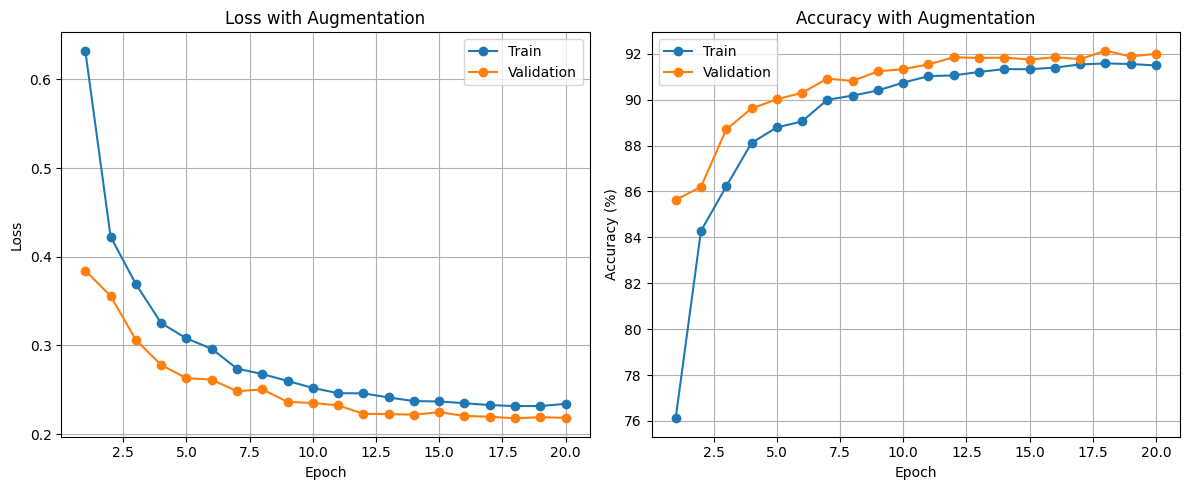

In [124]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", label="Train")
plt.plot(epochs, val_losses, marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss with Augmentation")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o", label="Train")
plt.plot(epochs, val_accuracies, marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy with Augmentation")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [125]:
import numpy as np

aug_best_epoch_idx = int(np.argmin(val_losses))
print('Augmented experiment summary')
print('Epochs:', len(val_losses))
print('Best validation accuracy:', f'{max(val_accuracies):.2f}%')
print('Best epoch by validation loss:', aug_best_epoch_idx + 1)
print('Best validation loss:', f'{val_losses[aug_best_epoch_idx]:.4f}')
print('Accuracy at best-loss epoch:', f'{val_accuracies[aug_best_epoch_idx]:.2f}%')
assert aug_best_epoch == aug_best_epoch_idx + 1

Augmented experiment summary
Epochs: 20
Best validation accuracy: 92.13%
Best epoch by validation loss: 18
Best validation loss: 0.2178
Accuracy at best-loss epoch: 92.13%


### 5.3 Augmented-experiment summary

From the **saved run**, the augmented configuration achieved its lowest validation loss of **0.2178 at epoch 18**, with **92.13% validation accuracy** at that epoch. These are **validation** metrics; they must not be presented as test-set results.


In [126]:
# Compare validation *losses* at their best epochs; retain one checkpoint per configuration.
experiments = {
    'Normalized baseline': {
        'val_loss': float(best_val_loss),
        'epoch': int(best_epoch),
        'checkpoint': 'best_fashion_cnn.pth',
    },
    'Affine augmentation + StepLR': {
        'val_loss': float(aug_best_val_loss),
        'epoch': int(aug_best_epoch),
        'checkpoint': aug_checkpoint,
    },
}
for name, info in experiments.items():
    print(f"{name}: best val loss={info['val_loss']:.4f} (epoch {info['epoch']})")

selected_name = min(experiments, key=lambda key: experiments[key]['val_loss'])
selected = experiments[selected_name]
print('Selected from validation only:', selected_name)
print('Checkpoint:', selected['checkpoint'])

Normalized baseline: best val loss=0.2158 (epoch 8)
Affine augmentation + StepLR: best val loss=0.2178 (epoch 18)
Selected from validation only: Normalized baseline
Checkpoint: best_fashion_cnn.pth


## 6. Model comparison and selection

Both experiments are compared using the **minimum observed validation cross-entropy loss**. The checkpoints are selected independently, then the configuration with the lower best validation loss is chosen for final evaluation.

| Configuration | Epochs trained | Best epoch by validation loss | Minimum validation loss |
|---|---:|---:|---:|
| Normalized baseline | 20 | 8 | **0.2158** |
| Affine augmentation + StepLR | 20 | 18 | **0.2178** |

In the saved run, the **normalized baseline** was selected because **0.2158 < 0.2178**. The difference is small (**0.0020 loss units**) and arises from a single train/validation split and seed; it is not sufficient evidence that augmentation is generally harmful. A stronger comparison would include multiple random seeds and an augmentation-only ablation.


In [127]:
# Load whichever candidate won the validation comparison.
selected_model = FashionCNN().to(device)
selected_state = torch.load(selected['checkpoint'], map_location=device, weights_only=True)
selected_model.load_state_dict(selected_state)
selected_model.eval()

print('Selected model:', selected_name)
print('Selected epoch:', selected['epoch'])
print('Selected validation loss:', f"{selected['val_loss']:.4f}")

Selected model: Normalized baseline
Selected epoch: 8
Selected validation loss: 0.2158


### 6.1 Restore the selected checkpoint

The best weights are loaded from disk into a fresh instance of the same architecture and the model is placed in evaluation mode. The final test metrics therefore refer to the **selected best checkpoint**, not necessarily the model from the last training epoch.


In [128]:
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=clean_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

## 7. Held-out test evaluation

Only after choosing the configuration from validation results is the separate **10,000-image test set** loaded. The following cells calculate predictions without gradient tracking, then report overall accuracy and macro-averaged precision, recall, and F1-score.

For one class, **precision = TP/(TP + FP)** and **recall = TP/(TP + FN)**; **F1 = 2PR/(P + R)** when its denominator is nonzero. Macro averaging computes each metric separately for the 10 classes, then takes their unweighted mean.


In [129]:
selected_model.eval()

test_correct = 0
test_total = 0

test_predictions = []
test_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = selected_model(images)

        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy()
        )

test_accuracy = 100 * test_correct / test_total

print(f"Final Test Accuracy: {test_accuracy:.2f}%")

Final Test Accuracy: 91.81%


In [130]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(
    test_labels, test_predictions
)

precision = precision_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

recall = recall_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

f1 = f1_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Test Accuracy: 0.9181
Precision: 0.9178
Recall: 0.9181
F1-score: 0.9177


### 7.1 Test metrics from the saved run

| Metric | Value |
|---|---:|
| Test accuracy | **91.81%** |
| Macro precision | **91.78%** |
| Macro recall | **91.81%** |
| Macro F1-score | **91.77%** |

These results describe the **selected normalized baseline checkpoint** in the stored execution. The metrics are calculated by the next cell, rather than being hard-coded into the evaluation logic. Since Fashion-MNIST has 1,000 test examples per class, the macro recall equals overall accuracy for this balanced test set.


In [131]:
class_names = test_dataset.classes

print(
    classification_report(
        test_labels,
        test_predictions,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.85      0.86      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.86      0.88      0.87      1000
       Dress       0.91      0.94      0.93      1000
        Coat       0.86      0.90      0.88      1000
      Sandal       0.98      0.99      0.98      1000
       Shirt       0.78      0.73      0.76      1000
     Sneaker       0.95      0.98      0.96      1000
         Bag       0.99      0.98      0.98      1000
  Ankle boot       0.98      0.95      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



### 7.2 Per-class performance

The classification report helps identify categories with weaker precision, recall, or F1-score, which aggregate accuracy alone can hide. A low recall for a class means many images from that class are incorrectly assigned to other classes.


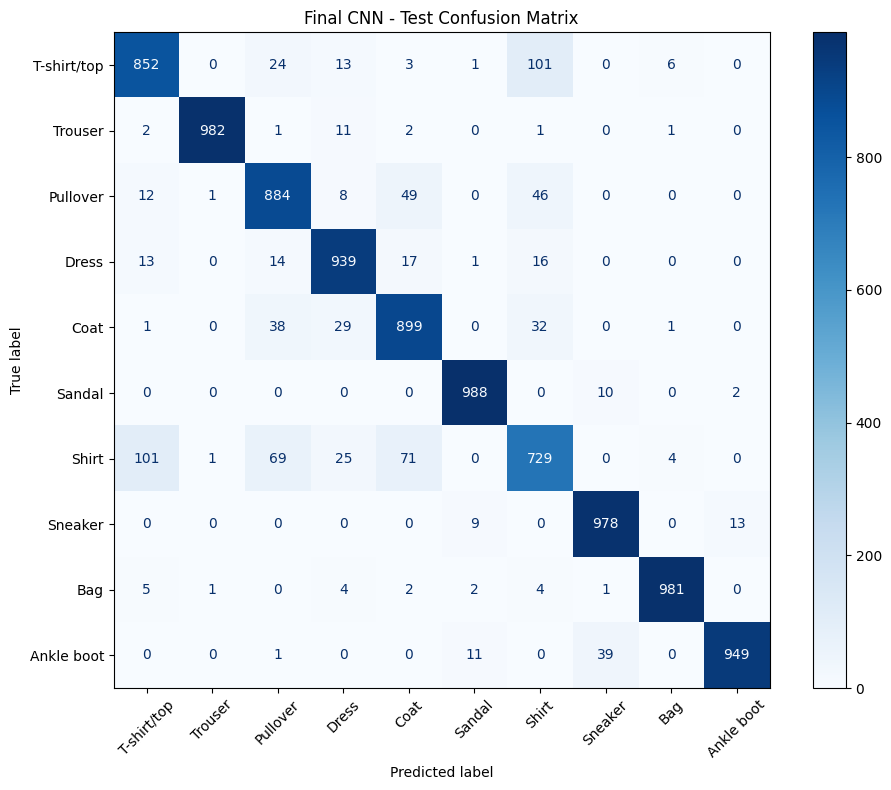

In [132]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

cm_final = confusion_matrix(
    test_labels,
    test_predictions,
    labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Final CNN - Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 7.3 Confusion matrix

Each **row** corresponds to the true class and each **column** to the predicted class. Diagonal entries are correct classifications; off-diagonal entries identify specific confusions. The visualization supports targeted error analysis instead of relying solely on a single accuracy score.


In [133]:
errors = cm_final.copy()
np.fill_diagonal(errors, 0)
indices = np.argsort(errors.ravel())[::-1]
error_total = int(errors.sum())
print(f'Total errors: {error_total} / {len(test_labels)}')
print('Top 5 directed classification errors:')
for idx in indices[:5]:
    true_idx, pred_idx = np.unravel_index(idx, errors.shape)
    print(f'  {class_names[true_idx]} -> {class_names[pred_idx]}: {errors[true_idx, pred_idx]}')
top_five_total = int(errors.ravel()[indices[:5]].sum())
print(f'Top 5 fraction of errors: {100 * top_five_total / error_total:.1f}%' if error_total else 'No errors')

Total errors: 819 / 10000
Top 5 directed classification errors:
  T-shirt/top -> Shirt: 101
  Shirt -> T-shirt/top: 101
  Shirt -> Coat: 71
  Shirt -> Pullover: 69
  Pullover -> Coat: 49
Top 5 fraction of errors: 47.7%


### 7.4 Most common classification mistakes

In the saved run there were **819 misclassifications** among 10,000 test examples. The five most frequent **directed** confusions were:

| True class → predicted class | Count |
|---|---:|
| T-shirt/top → Shirt | 101 |
| Shirt → T-shirt/top | 101 |
| Shirt → Coat | 71 |
| Shirt → Pullover | 69 |
| Pullover → Coat | 49 |

Together these account for **391 / 819 ≈ 47.7%** of test errors. All five involve visually related upper-body garments, suggesting that their similar outlines and the low input resolution contribute to difficult distinctions. This is a **plausible interpretation**, not proof of the underlying cause.


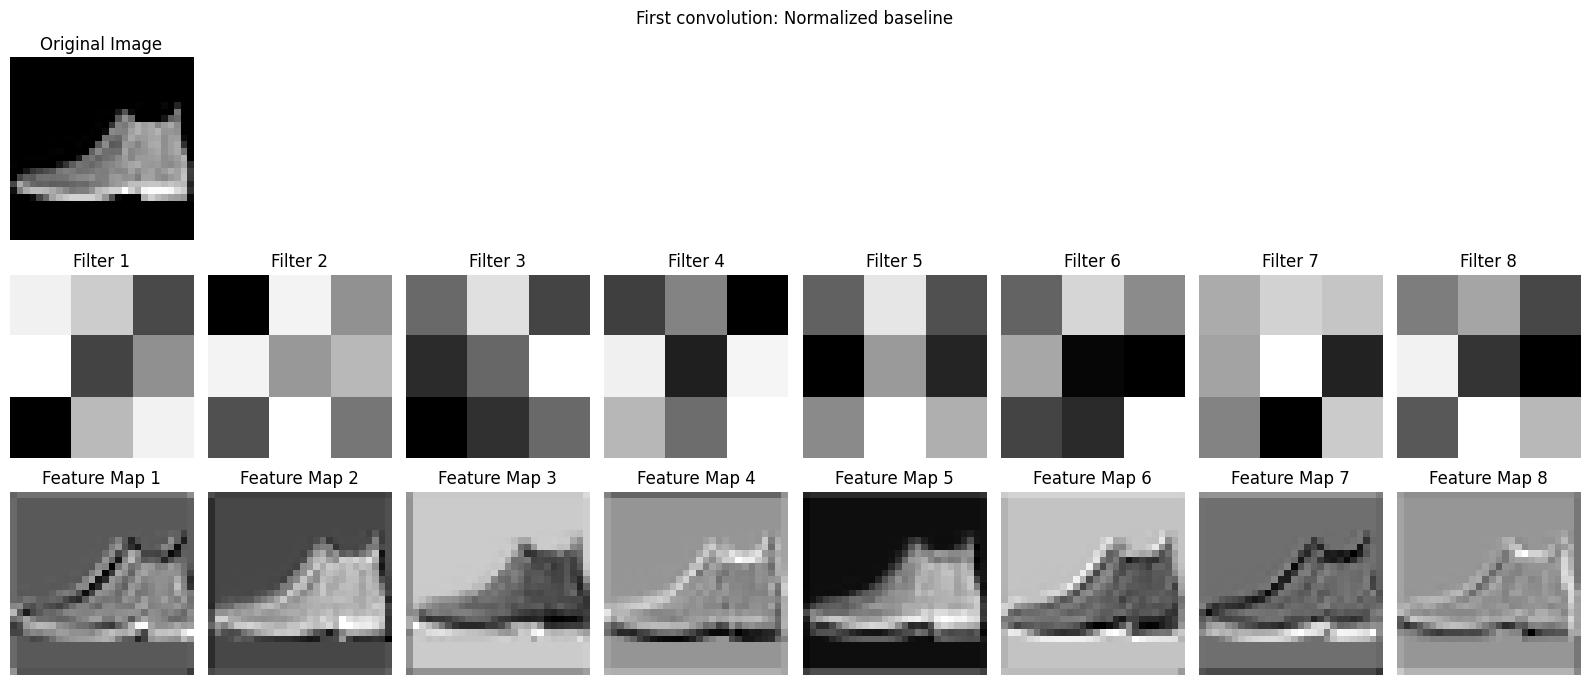

In [134]:
import numpy as np
import matplotlib.pyplot as plt

# Set model to evaluation mode
selected_model.eval()

# Get the first test image
image, label = test_dataset[0]
x = image.unsqueeze(0).to(device)

# Extract feature maps
with torch.no_grad():
    feature_maps = selected_model.features[0](x)

# Extract learned filters
filters = selected_model.features[0].weight.detach().cpu()
feature_maps = feature_maps.squeeze(0).cpu()

# Create visualization
fig, axes = plt.subplots(3, 8, figsize=(16, 7))

# Original image
original = image.squeeze() * 0.3530 + 0.2860

axes[0, 0].imshow(original.numpy(), cmap="gray")
axes[0, 0].set_title("Original Image")
fig.suptitle(f"First convolution: {selected_name}", fontsize=12)

for ax in axes[0, 1:]:
    ax.axis("off")

# Learned filters
for i in range(8):
    axes[1, i].imshow(filters[i, 0].numpy(), cmap="gray")
    axes[1, i].set_title(f"Filter {i+1}")

# Feature maps
for i in range(8):
    axes[2, i].imshow(feature_maps[i].numpy(), cmap="gray")
    axes[2, i].set_title(f"Feature Map {i+1}")

# Remove axes
for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

# Save figure for the report
plt.savefig(
    "final_filters_and_maps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Interpreting learned representations

### 8.1 First convolutional layer

The next figure visualizes the original image, eight learned **3 × 3** filters, and the corresponding **28 × 28 pre-ReLU feature maps**. Different filters respond to different local intensity patterns. Their maps can reveal spatial structures such as boundaries, but assigning a precise semantic meaning to each filter would require further analysis.

Each `imshow` panel may use its own color scale, so brightness cannot be compared across maps as a quantitative measure of activation strength without consistent limits.


Second-layer feature map tensor: (64, 14, 14)


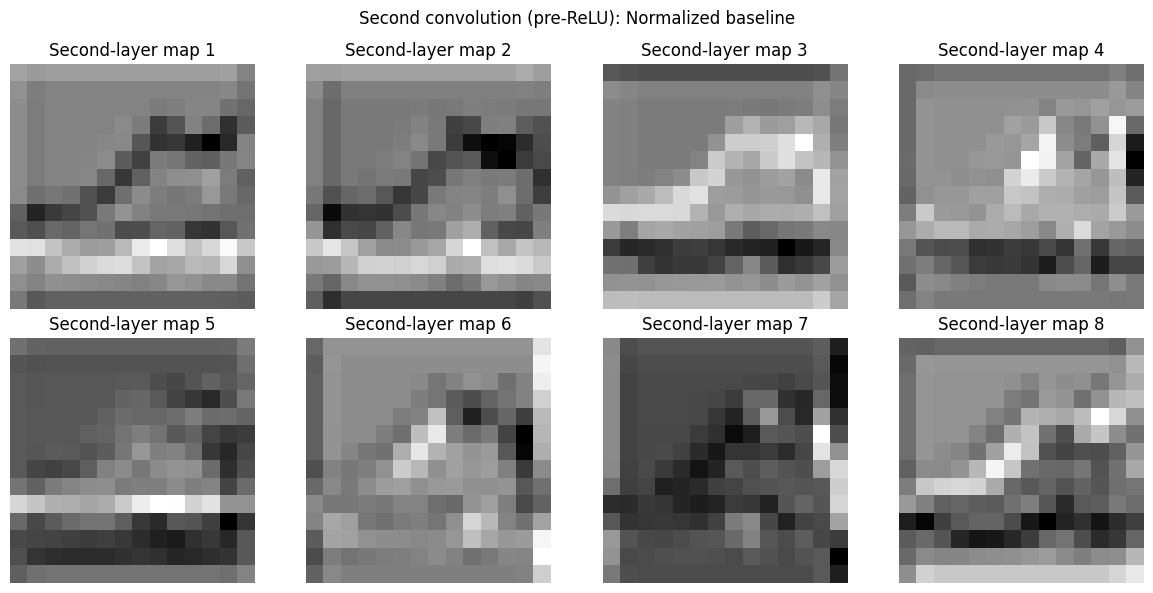

In [135]:
# Feature maps from the SECOND convolutional layer (before ReLU/MaxPooling).
# The first block maps [batch, 1, 28, 28] -> [batch, 32, 14, 14].
selected_model.eval()
image, label = test_dataset[0]
x = image.unsqueeze(0).to(device)

with torch.no_grad():
    first_block_output = selected_model.features[:3](x)
    second_layer_output = selected_model.features[3](first_block_output)

second_maps = second_layer_output.squeeze(0).cpu()
print('Second-layer feature map tensor:', tuple(second_maps.shape))  # (64, 14, 14)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(second_maps[i].numpy(), cmap='gray')
    ax.set_title(f'Second-layer map {i + 1}')
    ax.axis('off')

fig.suptitle(f'Second convolution (pre-ReLU): {selected_name}', fontsize=12)
plt.tight_layout()
plt.savefig('second_layer_feature_maps.png', dpi=300, bbox_inches='tight')
plt.show()


### 8.2 Second convolutional layer

The second-layer feature maps are computed after the **first convolution + ReLU + max pooling**, followed by the **second convolution**. They have shape **64 × 14 × 14** for one image, and the figure displays eight of these maps before the second ReLU and pooling.

Compared with the first convolution, these representations combine information from multiple earlier channels and operate at a reduced spatial resolution. They illustrate hierarchical feature extraction without demonstrating that any single map is a particular object detector.


In [136]:
# Export the live run's model choice and metrics (no hard-coded test results).
import csv
with open('final_results.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['metric', 'value'])
    writer.writerows([
        ('selected_configuration', selected_name),
        ('selected_epoch', selected['epoch']),
        ('selected_validation_loss', selected['val_loss']),
        ('test_accuracy', accuracy),
        ('macro_precision', precision),
        ('macro_recall', recall),
        ('macro_f1', f1),
        ('test_examples', len(test_labels)),
    ])
print('Saved final_results.csv')

Saved final_results.csv


## 9. Export and reproducibility notes

The final cell exports the **selected configuration, its checkpoint epoch and validation loss, and the test metrics actually computed in the current session** to `final_results.csv`. Saved inline plots remain part of the notebook, while the plotting cells also create PNG files in the runtime for use in the accompanying report.

For a reproducible submission, run the notebook in order from a fresh runtime, verify that both checkpoint files are generated, and save the notebook after all results and figures appear. Results can vary slightly across runs.
